Linear Regression: y = W*x + B

When given data, we typically try to draw a line of best fit. And this is the algorithim via which we do it. 

This line of best fit is used to help make predictions about any input given. For an example if we would liek to rpedict the grades one could get from a certain amount of studying. 

And the goal for linear regression is to choose out of every possible line, the one whose predictions miss the real data by the least, where you square each miss before adding them up.


In [20]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [21]:
data = {'x' : [1,2,3,4],
        'y' : [3,5,6,8]}

df = pd.DataFrame(data)

df

,x,y
0,1,3
1,2,5
2,3,6
3,4,8


<Axes: title={'center': 'X vs Y'}, xlabel='x', ylabel='y'>

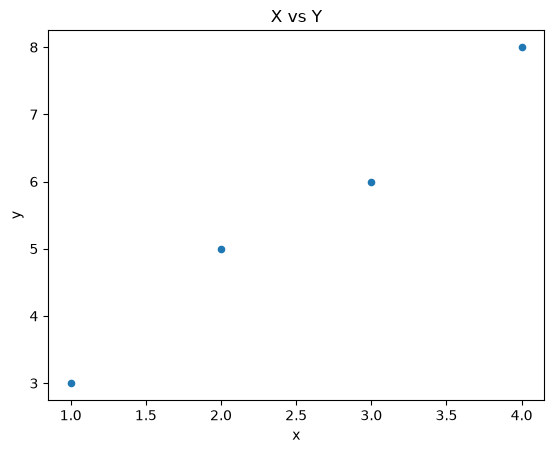

In [22]:
df.plot(x = 'x', y= 'y', kind="scatter", title= "X vs Y")

We have our data, now we need a line that helps minimise the loss/error: 
Line:   ŷ = w·x + b
Error:  L(w, b) = (1/n) · Σᵢ (yᵢ − ŷᵢ)²

n       - no. of elements 
y_i     - the actual value 
ŷ_i     - the predicted value 

Lets start with L(0,0) => ŷ = x  

Lets set up what we need: 
1. Learning Rate 
2. Max Iterations 
3. The loss log 
4. The W and B value 

In [ ]:
class LinearRegression: 
    def __init__(self, lr = 0.05, iteration = 1000):
        self.lr = lr 
        self.iter = iteration
        self.w = None 
        self.b = 0 
        self.loss_log = []


# Lets make the predictor, we return an array of the predictions 
    def predictor(self, X):
        predictions = []
        X = np.array(X)
        for num in X: 
            if self.w is None: 
                pred = num + self.b
            else: 
                pred = (self.w * num) + self.b
            
            predictions.append(pred)

        return predictions

# Lets now calculate our MSE, we will return another array of our residuals 
    def MSE(self, y, X):
        n = len(X)
        pred_Y = self.predictor(X)
        Actual_Y = y.to_numpy()

        if len(pred_Y) != len(Actual_Y):
            return "There is an issue here"
        else: 
            MSE = 0
            for i in range(n):
                temp = (Actual_Y[i] - pred_Y[i])**2
                MSE += temp/n

            return MSE
    
    def residuals(self, X, y):
        residue = []
        n = len(X)
        pred_Y = self.predictor(X)
        Actual_Y = y.to_numpy()

        for i in range(n):
            residue.append(Actual_Y[i]-pred_Y[i])

        residue = np.array(residue)

        return residue

    def fit(self, X, y):
        n, c = X.shape
        self.b = 0.0
        self.w = 0.0  
        self.loss_log = []

        for _ in range(self.iter): 
            residue = self.residuals(X,y) 
            self.loss_log.append(self.MSE(y,X))
            # w gradient 
            grad_w = (-2/n) * np.sum(residue * np.array(X))
            # b gradient
            grad_b = (-2/n) * np.sum(residue)
            # TODO 6: one step downhill for w and b
            self.w = self.w - self.lr*grad_w
            self.b = self.b - self.lr*grad_b

        return self 



This is with Claudes help to fix my code 

After 1 step:     w = 1.575, b = 0.550   (expected 1.575, 0.550)
After 2000 steps: w = 1.6000, b = 1.5000   (expected 1.6, 1.5)


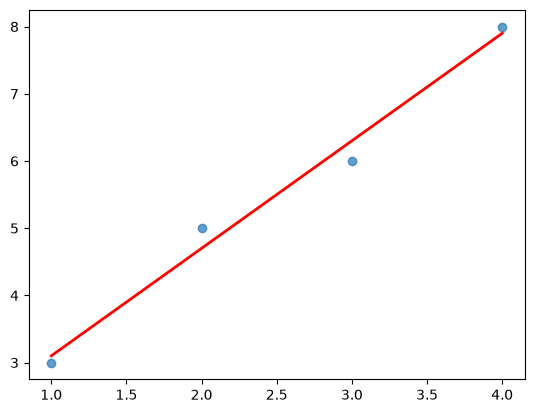

In [25]:
class LinearRegression: 
    def __init__(self, lr = 0.05, iteration = 1000):
        self.lr = lr 
        self.iter = iteration
        self.w = None 
        self.b = 0 
        self.loss_log = []

    def _flat(self, data):
        return np.asarray(data, dtype=float).reshape(-1)

# Lets make the predictor, we return an array of the predictions 
    def predictor(self, X):
        predictions = []

        X = self._flat(X)

        if self.w is None: 
            raise ValueError("gg mofo ur code broken")
        
        for num in X: 
            pred = (self.w * num) + self.b
            predictions.append(pred)

        return np.array(predictions)

# Lets now calculate our MSE, we will return another array of our residuals 
    def MSE(self, y, X):
        residue = self.residuals(X, y)
        n = len(residue)
        
        MSE = 0
        for i in range(n):
            MSE += residue**2 /n

        return MSE
    
    def residuals(self, X, y):
        residue = []
        pred_Y = self.predictor(X)
        n = len(pred_Y)
        Actual_Y = self._flat(y)

        for i in range(n):
            residue.append(Actual_Y[i]-pred_Y[i])

        return np.array(residue)

    def fit(self, X, y):
        X = self._flat(X)
        y = self._flat(y)
        n = len(X)
        self.b = 0.0
        self.w = 0.0  
        self.loss_log = []

        for _ in range(self.iter): 
            residue = self.residuals(X,y) 
            self.loss_log.append(np.mean(residue**2))
            # w gradient 
            grad_w = (-2/n) * np.sum(residue * X)
            # b gradient
            grad_b = (-2/n) * np.sum(residue)
            # TODO 6: one step downhill for w and b
            self.w = self.w - (self.lr * grad_w)
            self.b = self.b - (self.lr * grad_b)

        return self 

if __name__ == "__main__":
    # The four students from the lesson
    X = np.array([1.0, 2.0, 3.0, 4.0])
    y = np.array([3.0, 5.0, 6.0, 8.0])

    one_step = LinearRegression(lr=0.05, iteration=1).fit(X, y)
    print(f"After 1 step:     w = {one_step.w:.3f}, b = {one_step.b:.3f}   (expected 1.575, 0.550)")

    model = LinearRegression(lr=0.05, iteration=2000).fit(X, y)
    print(f"After 2000 steps: w = {model.w:.4f}, b = {model.b:.4f}   (expected 1.6, 1.5)")

    plt.scatter(x= df["x"], y=df["y"], label = 'data', alpha =0.7)
    x_vals = np.linspace(df['x'].min(), df['x'].max(), 200)
    y_vals = model.w * x_vals + model.b

    plt.plot(
    x_vals, y_vals, color='red', linewidth=2, label='Equation: ')


Real Dataset time YAYAYAYYAY!

https://www.kaggle.com/datasets/abhishek14398/salary-dataset-simple-linear-regression?resource=download


In [30]:
real_data = pd.read_csv("Salary_dataset.csv")

In [31]:
real_data.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [32]:
real_data = real_data.drop(columns=['Unnamed: 0'])

real_data.head()


,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


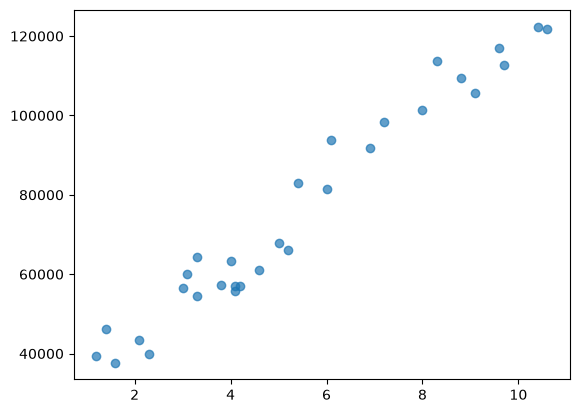

In [38]:
plt.scatter(x= real_data["YearsExperience"], y=real_data['Salary'], label = 'data', alpha =0.7)

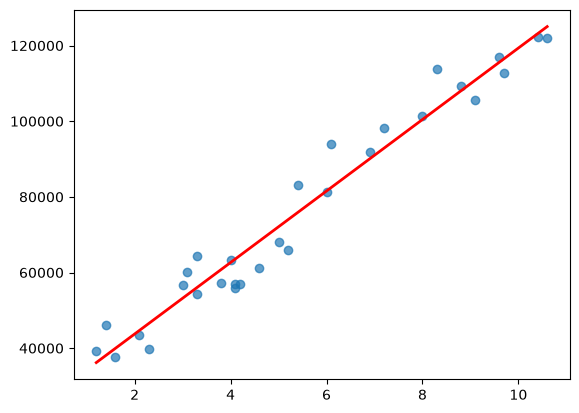

In [37]:
if __name__ == "__main__":
    X = real_data.YearsExperience
    Y = real_data.Salary

    modelnew = LinearRegression(lr = 0.01, iteration=5000).fit(X=X,y=Y)

    plt.scatter(x= real_data["YearsExperience"], y=real_data['Salary'], label = 'data', alpha =0.7)
    x_vals = np.linspace(real_data["YearsExperience"].min(), real_data["YearsExperience"].max(), 200)
    y_vals = modelnew.w * x_vals + modelnew.b

    plt.plot(
    x_vals, y_vals, color='red', linewidth=2, label='Equation: ')